### Sistema de Apoio à Decisão Corporativa com Multiagentes (LangGraph + Gemini)

##### Configuração Inicial do Ambiente

#####Importando as dependências necessárias para uso do Langraph e Langchain

In [1]:
import sys
print(sys.executable)

c:\Unicamp\MC032\Estudo_Dirigido\.venv\Scripts\python.exe


Importação das principais biblíotecas utilizadas API (Gemini) e gerenciamento do modelo como a arquitetura do grafo e ajuste de outputs em formato estruturado(pydantic)

In [2]:
import os
from typing import TypedDict, List, Optional, Literal
from pydantic import BaseModel, Field

from langchain_core.prompts import ChatPromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import StateGraph, START, END

# Leitura da chave de API do Google Gemini do arquivo .env
import os
from pathlib import Path
from dotenv import load_dotenv

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

load_dotenv(PROJECT_ROOT / ".env")

if not os.getenv("GOOGLE_API_KEY"):
    from getpass import getpass

    api_key = getpass("Digite sua Google API key: ").strip()
    if api_key:
        os.environ["GOOGLE_API_KEY"] = api_key
    else:
        raise RuntimeError(
            "A chave da API não foi informada. Configure GOOGLE_API_KEY no arquivo .env."
        )

# Instanciação com o modelo recomendado
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
)

#Caminhos de arquivos
INPUT_CSV = PROJECT_ROOT / "data" / "propostas_avaliacao.csv"
OUTPUT_CSV = PROJECT_ROOT / "results" / "resultados_experimento2_mc032.csv"

OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)

In [3]:
# Teste de leitura do arquivo CSV
import pandas as pd
df = pd.read_csv(INPUT_CSV)
df.head()

,id,texto_proposta,status_esperado
0,PRJ-001,Objetivo: Modernizar o sistema de gestão de ar...,FUND
1,PRJ-002,Objetivo: Implementar uma plataforma corporati...,FUND
2,PRJ-003,Objetivo: Implantar um sistema de Manutenção P...,FUND
3,PRJ-004,Objetivo: Estruturar um portal unificado de On...,FUND
4,PRJ-005,Objetivo: Desenvolver e lançar um aplicativo m...,REVISE


Montagem de Dados e Estado Global:

O objetivo é definir a saída estruturada de cada especialista e estado central que transitará pelo grafo

In [4]:
# 1. Esquema de avaliação individual de cada especialista sem o blocker_severity
class AgentOpinion(BaseModel):
    agent_name: str = Field(description="Nome da especialidade avaliada")
    score: float = Field(ge=0, le=10, description="Nota de 0 a 10 atribuída pelo especialista")
    strengths: List[str] = Field(description="Pontos fortes identificados na proposta")
    concerns: List[str] = Field(description="Fraquezas, riscos ou premissas frágeis detectadas")

# 2. Esquema da decisão final
class DecisionOutcome(BaseModel):
    final_score: float = Field(ge=0, le=10)
    decision: Literal["FUND", "REVISE", "REJECT"]
    executive_summary: str
    action_plan_or_reasons: List[str]

# 3. Estado compartilhado do grafo
class MultiAgentState(TypedDict):
    project_proposal: str
    evaluations: List[AgentOpinion]
    debate_summary: Optional[str]
    final_decision: Optional[DecisionOutcome]

### Explicação dos Componentes e Papéis dos Agentes

#### 1. Estruturas de Dados (Classes)
* **`AgentOpinion`**: Define o formato estruturado de saída para cada especialista. Ele garante que cada agente retorne de forma consistente uma nota de 0 a 10, pontos fortes, preocupações e o indicador crítico (`critical_blocker`), que atua como um veto imediato de governança.
* **`DecisionOutcome`**: Representa o veredito final consolidado pelo comitê, contendo a nota ponderada final, a decisão estruturada (`FUND`, `REVISE` ou `REJECT`), um sumário executivo detalhado e o plano de ação sugerido.
* **`MultiAgentState`**: É o estado centralizado e compartilhado que transita pelas etapas do grafo do LangGraph, acumulando o histórico de avaliações de todos os agentes.

#### 2. O Papel de Cada Agente Especialista
* **Strategic Agent**: Avalia o alinhamento do projeto com os objetivos de longo prazo (OKRs) e a proposta de valor para a empresa.
* **Financial Agent**: Analisa a viabilidade financeira, incluindo métricas como ROI, payback, projeção de custos e fluxo de caixa.
* **Risk Agent**: Mapeia vulnerabilidades, conformidade regulatória (como LGPD), e riscos jurídicos ou operacionais.
* **Technical Agent**: Verifica se há viabilidade tecnológica, robustez de arquitetura e capacidade de escala da solução.
* **Market Agent**: Analisa o mercado de atuação, concorrência direta e os diferenciais competitivos da proposta.
* **Resource Agent**: Valida se o cronograma é realista perante a capacidade operacional e disponibilidade de pessoal técnico.

##### Criação dos Nós (Especialistas, Debate e Decisão)

1. Função geradora para instanciar as 6 especialidades;
2. O nó de debate/crítica cruzada;
3. O comitê de decisão final utilizando Média Ponderada (MCDA).

In [5]:
import time
from langchain_core.prompts import ChatPromptTemplate

# 1. Função fábrica calibrada para os Agentes Sequenciais
def create_sequential_evaluator(role_name: str, criteria: str):
    prompt = ChatPromptTemplate.from_messages([
        ("system", f"""Você é o {role_name} de um comitê executivo. Avalie a proposta sob a ótica: {criteria}.

        DIRETRIZES DE AVALIAÇÃO E CALIBRAÇÃO DE NOTAS:
        - Analise detalhadamente todos os aspectos do projeto sob sua perspectiva de especialidade.
        - Atribua uma nota de 0 a 10 de forma justa, pragmática e criteriosa.
        - CALIBRAÇÃO CRÍTICA DE NOTA: Não atribua notas excessivamente baixas (abaixo de 4.0) por pequenas fraquezas, pendências ou riscos mitigáveis.
          * Se o projeto for viável mas apresentar problemas moderados de cronograma, carência pontual de equipe ou pequenas lacunas técnicas que podem ser ajustadas em uma revisão, utilize notas intermediárias na faixa de 4.5 a 6.5.
          * Notas abaixo de 4.0 devem ser reservadas estritamente para falhas catastróficas, completa inviabilidade técnica/financeira, ou ilegalidades explícitas no projeto."""),
        ("human", "Analise a proposta corporativa abaixo e gere seu parecer estruturado:\n\n{proposal}")
    ])

    # Conecta o prompt ao LLM (Gemini)
    chain = prompt | llm.with_structured_output(AgentOpinion)

    def node_fn(state: MultiAgentState):
        print(f"-> {role_name} iniciando avaliação...")
        # Pausa para respeitar o limite de 5 requisições por minuto da API
        time.sleep(12)

        # Passando a proposta de projeto para a avaliação do modelo e atualiza o nome do agente
        opinion = chain.invoke({"proposal": state["project_proposal"]})
        opinion.agent_name = role_name

        print(f"✓ {role_name} concluiu a análise (Nota: {opinion.score}/10).")

        current_evaluations = list(state.get("evaluations", []))
        current_evaluations.append(opinion)
        return {"evaluations": current_evaluations}

    return node_fn

# 2. Instanciação de cada função de nó especialista com critérios padronizados
strategic_node = create_sequential_evaluator("Strategic Agent", "Alinhamento com estratégia corporativa, proposta de valor e OKRs")
financial_node = create_sequential_evaluator("Financial Agent", "ROI, payback, rentabilidade, premissas de custos e fluxo de caixa")
risk_node = create_sequential_evaluator("Risk Agent", "Riscos regulatórios, jurídicos, conformidade e vulnerabilidades operacionais")
technical_node = create_sequential_evaluator("Technical Agent", "Viabilidade tecnológica, arquitetura de sistemas e escala técnica")
market_node = create_sequential_evaluator("Market Agent", "Tamanho de mercado (TAM/SAM), concorrência e diferencial competitivo")
resource_node = create_sequential_evaluator("Resource Agent", "Disponibilidade de time, capacidade operacional e prazos de entrega")

# 3. Nó de Debate / Critique
def debate_critique_node(state: MultiAgentState):
    print("-> Iniciando debate cruzado do comitê...")
    opinions_text = "\n\n".join([
        f"**{op.agent_name}** (Nota: {op.score}/10):\n"
        f"- Pontos Fortes: {', '.join(op.strengths)}\n"
        f"- Preocupações: {', '.join(op.concerns)}"
        for op in state["evaluations"]
    ])

    prompt = f"""Você é o mediador do comitê executivo.
Analise os pareceres abaixo e elabore uma crítica cruzada, confrontando inconsistências entre as áreas:

Pareceres:\n{opinions_text}"""
    critique = llm.invoke(prompt).content
    print("✓ Debate cruzado finalizado.")
    return {"debate_summary": critique}

# 4. Nó de Decisão Final com Média Ponderada Redefinida (Decisão 100% por Notas)
def decision_agent_node(state: MultiAgentState):
    print("-> Comitê deliberando a decisão final...")

    # Distribuição equilibrada de pesos
    pesos = {
        "Strategic Agent": 0.20,
        "Financial Agent": 0.20,
        "Risk Agent": 0.20,
        "Technical Agent": 0.15,
        "Market Agent": 0.10,
        "Resource Agent": 0.15
    }

    # Cálculo da nota ponderada
    avaliacoes = state["evaluations"]
    if avaliacoes:
        nota_final = round(sum(op.score * pesos.get(op.agent_name, 1/6) for op in avaliacoes), 2)
    else:
        nota_final = 0.0

    # Regra de Decisão calibrada baseada unicamente nas faixas de notas
    if nota_final < 4.0:
        status_decisao = "REJECT"
    elif 4.0 <= nota_final < 8.0:
        status_decisao = "REVISE"
    else:
        status_decisao = "FUND"

    print(f"   [Sistema] Média Ponderada: {nota_final}/10 -> Veredito: {status_decisao}")

    # LLM como redator executivo
    prompt = ChatPromptTemplate.from_messages([
        ("system", """Você é o Diretor Executivo (C-Level).
        A diretoria já calculou matematicamente a nota final ponderada do projeto e o veredito.
        Sua ÚNICA tarefa é ler o debate e escrever o 'Sumário Executivo' justificando a decisão abaixo:

        VEREDITO DEFINIDO PELO SISTEMA: {status}
        NOTA FINAL CALCULADA: {nota}/10
        """),
        ("human", "Debate e Conclusões:\n{debate}\n\nProposta Original:\n{proposal}")
    ])

    class ExecutiveSummary(BaseModel):
        executive_summary: str = Field(description="Resumo executivo justificando a decisão e a nota")
        action_plan_or_reasons: List[str] = Field(description="Lista de próximos passos ou motivos da reprovação")

    chain = prompt | llm.with_structured_output(ExecutiveSummary)
    resumo_llm = chain.invoke({
        "status": status_decisao,
        "nota": nota_final,
        "debate": state["debate_summary"],
        "proposal": state["project_proposal"]
    })

    decision = DecisionOutcome(
        final_score=nota_final,
        decision=status_decisao,
        executive_summary=resumo_llm.executive_summary,
        action_plan_or_reasons=resumo_llm.action_plan_or_reasons
    )

    print("Decisão final estruturada e auditável baseada estritamente em critérios multicritério.")
    return {"final_decision": decision}

In [6]:
def proposal_optimizer_node(state: MultiAgentState):
    print("-> [Optimizer] Otimizando a proposta com base nas ressalvas do comitê...")

    prompt = f"""Você é um Consultor de Projetos sênior.
    Sua tarefa é ajustar e otimizar a proposta de projeto original com base estrita no parecer e nas críticas do comitê de especialistas.

    PROPOSTA ORIGINAL:
    {state['project_proposal']}

    CRÍTICAS E RESSALVAS DO COMITÊ:
    {state['debate_summary']}

    Gere uma nova versão revisada e otimizada da proposta que resolva as fraquezas apontadas (como prazos irreais, falta de recursos ou riscos regulatórios/de segurança).
    """

    reformatted_proposal = llm.invoke(prompt).content
    print("✓ Proposta otimizada com sucesso para a nova rodada de avaliação.")

    # Retorna o estado com a proposta atualizada e limpa a lista de avaliações para que o comitê reavalie do zero
    return {
        "project_proposal": reformatted_proposal,
        "evaluations": [],
        "debate_summary": None,
        "final_decision": None
    }

Montagem do Grafo e Visualização

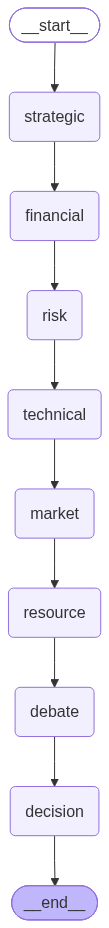

In [7]:
from langgraph.graph import StateGraph, START, END

builder_seq = StateGraph(MultiAgentState)

# Adiciona os nós no grafo
builder_seq.add_node("strategic", strategic_node)
builder_seq.add_node("financial", financial_node)
builder_seq.add_node("risk", risk_node)
builder_seq.add_node("technical", technical_node)
builder_seq.add_node("market", market_node)
builder_seq.add_node("resource", resource_node)
builder_seq.add_node("debate", debate_critique_node)
builder_seq.add_node("decision", decision_agent_node)

# Encadeamento sequencial linear
builder_seq.add_edge(START, "strategic")
builder_seq.add_edge("strategic", "financial")
builder_seq.add_edge("financial", "risk")
builder_seq.add_edge("risk", "technical")
builder_seq.add_edge("technical", "market")
builder_seq.add_edge("market", "resource")
builder_seq.add_edge("resource", "debate")
builder_seq.add_edge("debate", "decision")
builder_seq.add_edge("decision", END)

# Compila o executável sequencial
app_seq = builder_seq.compile()


from IPython.display import Image, display

try:
    display(Image(app_seq.get_graph().draw_mermaid_png()))
except Exception:
    # Alternativa caso o serviço de conversão web de PNG do Mermaid falhe:
    from IPython.display import Markdown
    display(Markdown(f"```mermaid\n{app_seq.get_graph().draw_mermaid()}\n```"))

Execução e Inspeção dos Resultados

#### Configuração para Execução em Série (Sequencial)

Para garantir que o fluxo execute sem atingir o limite de 5 requisições por minuto (RPM) da API do Gemini, os setores especialistas foram ligados em **série (um após o outro)** no grafo, garantindo um intervalo de `time.sleep` de 12 segundos entre as chamadas da API. Isso é estritamente necessário visto que há uma limitação de Requisições por Minuto (RPM) na camada gratuita da API do Gemini.

In [8]:
##### Definição dos Cenários de Teste

In [9]:
# Exemplo de input REJECT
sample_project_reject = """
Proposta de Projeto: Expansão da Linha de Microcrédito via IA Autônoma
- Objetivo: Lançar esteira 100% automatizada de concessão de crédito para PMEs em 60 dias.
- Orçamento: R$ 500.000,00 estimados para infraestrutura e contratação de 1 cientista de dados.
- Retorno projetado: R$ 5M em carteira ativa no primeiro trimestre com taxa de inadimplência estimada em 1%.
- Riscos: Legislação do Banco Central sobre decisões de crédito automatizadas ainda em regulamentação.
"""

# Exemplo 2 de input REJECT
sample_project_reject2 = """
Proposta de Projeto: Substituição do Call Center Nível 1 por Chatbot com IA Generativa
- Objetivo: Automatizar 60% do atendimento inicial ao cliente utilizando um LLM open-source (Llama-3) ajustado para os nossos produtos, com lançamento em 3 meses.
- Orçamento: R$ 250.000,00 para aluguel de servidores com GPU na nuvem e alocação de 2 desenvolvedores plenos da equipe interna.
- Retorno projetado: Economia de R$ 1.5M anuais em custos de operação de call center terceirizado.
- Riscos: O modelo pode gerar respostas incorretas (alucinações) sobre regras de estorno e devolução. Além disso, não há clareza se a infraestrutura de servidores orçada suportará o volume de acessos simultâneos durante a Black Friday.
"""

# Exemplo de input REVISE
sample_project_revise = """
Proposta de Projeto: Substituição do Call Center Nível 1 por Chatbot com IA Generativa
- Objetivo: Automatizar 60% do atendimento inicial ao cliente utilizando um LLM open-source (Llama-3) ajustado para os nossos produtos, com lançamento em 3 meses.
- Orçamento: R$ 250.000,00 para aluguel de servidores com GPU na nuvem e alocação de 2 desenvolvedores plenos da equipe interna.
- Retorno projetado: Economia de R$ 1.5M anuais em custos de operação de call center terceirizado.
- Riscos: Atraso potencial de 2 semanas no cronograma devido à curva de aprendizagem da equipa com a nova tecnologia.
"""

# Exemplo de input FUND
sample_project_fund = """
Proposta de Projeto: Estruturação de Data Lake Corporativo para Business Intelligence
- Objetivo: Centralizar dados de vendas, marketing e finanças em uma arquitetura unificada (AWS S3 + Snowflake) no prazo de 6 meses.
- Orçamento: R$ 800.000,00 (Capex aprovado) para licenças de nuvem e contratação de consultoria externa especializada em Engenharia de Dados.
- Retorno projetado: Redução de 40% no tempo de geração de relatórios e aumento estimado de 15% nas vendas cruzadas (cross-sell) via insights de dados. Payback estimado em 14 meses.
- Riscos: Exposição de dados sensíveis de clientes (LGPD). Mitigação aprovada: A arquitetura já prevê anonimização nativa de dados e controle de acesso baseado em funções (RBAC), previamente validada pelo departamento Jurídico.
"""

In [10]:


# 3. Ponto de partida inicial da proposta no grafo sequencial

initial_state_seq = {
    "project_proposal": sample_project_revise,
    "evaluations": []
}

print("Iniciando avaliação do Comitê Executivo...\n")
try:
    result_seq = app_seq.invoke(initial_state_seq)

    # Exibe o resultado consolidado final
    decision_seq = result_seq["final_decision"]
    print("\n" + "="*50)
    print(f"Decisão final: {decision_seq.decision} | Nota: {decision_seq.final_score}/10")
    print("="*50)
    print(f"\nSumário Executivo:\n{decision_seq.executive_summary}\n")
    print("Próximos Passos / Motivos de Reprovação ou Ajuste:")
    for item in decision_seq.action_plan_or_reasons:
        print(f"- {item}")
except Exception as e:
    print(f"\nOcorreu um erro durante a execução: {e}")

Iniciando avaliação do Comitê Executivo...

-> Strategic Agent iniciando avaliação...
✓ Strategic Agent concluiu a análise (Nota: 8.5/10).
-> Financial Agent iniciando avaliação...
✓ Financial Agent concluiu a análise (Nota: 9.2/10).
-> Risk Agent iniciando avaliação...
✓ Risk Agent concluiu a análise (Nota: 6.5/10).
-> Technical Agent iniciando avaliação...
✓ Technical Agent concluiu a análise (Nota: 6.5/10).
-> Market Agent iniciando avaliação...
✓ Market Agent concluiu a análise (Nota: 8.5/10).
-> Resource Agent iniciando avaliação...
✓ Resource Agent concluiu a análise (Nota: 6.5/10).
-> Iniciando debate cruzado do comitê...
✓ Debate cruzado finalizado.
-> Comitê deliberando a decisão final...
   [Sistema] Média Ponderada: 7.64/10 -> Veredito: REVISE
Decisão final estruturada e auditável baseada estritamente em critérios multicritério.

Decisão final: REVISE | Nota: 7.64/10

Sumário Executivo:
O projeto apresenta excelente mérito financeiro, estratégico e de mercado, com forte pote

In [ ]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Caminho dos arquivos
csv_path = '/content/drive/MyDrive/Estudo_Dirigido/propostas_avaliacao.csv'
if not os.path.exists(csv_path):
    csv_path = 'propostas_avaliacao.csv'

# Carregar o dataset
csv_path = INPUT_CSV
if not csv_path.exists():
    raise FileNotFoundError(f"Dataset não encontrado: {csv_path}")

df_propostas = pd.read_csv(csv_path)
print(f"Dataset carregado com sucesso. Total de registros: {len(df_propostas)}")
display(df_propostas.head())

resultados = []

# 2. Iteração linha por linha para Batch Evaluation
for index, row in df_propostas.iterrows():
    id_proposta = row.get('id', index)
    texto_proposta = row['texto_proposta']
    status_esperado = row['status_esperado']

    print(f"\n[{index+1}/{len(df_propostas)}] Processando Proposta ID: {id_proposta}...")

    initial_state = {
        "project_proposal": texto_proposta,
        "evaluations": []
    }

    try:
        # Executa o grafo
        result = app_seq.invoke(initial_state)
        decision_outcome = result["final_decision"]

        veredito_sistema = decision_outcome.decision
        nota_ponderada = decision_outcome.final_score
        sumario_executivo = decision_outcome.executive_summary
        proximos_passos = "\n".join([f"- {item}" for item in decision_outcome.action_plan_or_reasons])
        acertou = (veredito_sistema == status_esperado)

        print(f"   -> Veredito Sistema: {veredito_sistema} | Esperado: {status_esperado} | Nota: {nota_ponderada} | Acertou: {acertou}")

        resultados.append({
            "id": id_proposta,
            "texto_proposta": texto_proposta,
            "status_esperado": status_esperado,
            "veredito_sistema": veredito_sistema,
            "nota_ponderada": nota_ponderada,
            "sumario_executivo": sumario_executivo,
            "proximos_passos_ou_motivos": proximos_passos,
            "acertou": acertou
        })

    except Exception as e:
        print(f"   [ERRO] Falha ao processar proposta {id_proposta}: {e}")
        resultados.append({
            "id": id_proposta,
            "texto_proposta": texto_proposta,
            "status_esperado": status_esperado,
            "veredito_sistema": "ERRO",
            "nota_ponderada": np.nan,
            "sumario_executivo": str(e),
            "proximos_passos_ou_motivos": "",
            "acertou": False
        })

    # 5. Pausa de segurança de 15 segundos para respeitar o limite de RPM (Gemini gratuito)
    if index < len(df_propostas) - 1:
        print("   Aguardando 15 segundos para próxima chamada (Evitar Limite de RPM)...")
        time.sleep(15)

# 6. Salvar os resultados em um novo arquivo CSV
df_resultados = pd.DataFrame(resultados)
OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)
df_resultados.to_csv(OUTPUT_CSV, index=False)
print("\n✓ Todos os resultados salvos com sucesso em 'resultados_experimento2_mc032.csv'")

# Filtrar erros para cálculo de métricas
df_validos = df_resultados[df_resultados['veredito_sistema'] != 'ERRO']
y_true = df_validos['status_esperado']
y_pred = df_validos['veredito_sistema']

# Classes de referência solicitadas
classes = ["FUND", "REVISE", "REJECT"]

# 7. Relatório de Classificação e Acurácia
acuracia = accuracy_score(y_true, y_pred)
print(f"\n==================================================")
print(f"Acurácia Global do Experimento: {acuracia * 100:.2f}%")
print(f"==================================================")
print("Classification Report:\n")
print(classification_report(y_true, y_pred, labels=classes, target_names=classes))

# Plotagem e salvamento da Matriz de Confusão
cm = confusion_matrix(y_true, y_pred, labels=classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes,
            cbar=False, annot_kws={"size": 16})

plt.title('Matriz de Confusão - Comitê Executivo (Experimento MC032)', fontsize=14, pad=15)
plt.xlabel('Veredito Previsto pelo Sistema', fontsize=12, labelpad=10)
plt.ylabel('Veredito Esperado (Gabarito)', fontsize=12, labelpad=10)
plt.tight_layout()

plt.savefig('matriz_confusao_mc032.png', dpi=300)
plt.show()
print("✓ Matriz de confusão visual gerada e salva como 'matriz_confusao_mc032.png'.")

Dataset carregado com sucesso. Total de registros: 10


,id,texto_proposta,status_esperado
0,PRJ-001,Objetivo: Modernizar o sistema de gestão de ar...,FUND
1,PRJ-002,Objetivo: Implementar uma plataforma corporati...,FUND
2,PRJ-003,Objetivo: Implantar um sistema de Manutenção P...,FUND
3,PRJ-004,Objetivo: Estruturar um portal unificado de On...,FUND
4,PRJ-005,Objetivo: Desenvolver e lançar um aplicativo m...,REVISE



[1/10] Processando Proposta ID: PRJ-001...
-> Strategic Agent iniciando avaliação...
✓ Strategic Agent concluiu a análise (Nota: 9.5/10).
-> Financial Agent iniciando avaliação...
✓ Financial Agent concluiu a análise (Nota: 8.5/10).
-> Risk Agent iniciando avaliação...
✓ Risk Agent concluiu a análise (Nota: 8.0/10).
-> Technical Agent iniciando avaliação...
✓ Technical Agent concluiu a análise (Nota: 8.5/10).
-> Market Agent iniciando avaliação...
✓ Market Agent concluiu a análise (Nota: 8.5/10).
-> Resource Agent iniciando avaliação...
✓ Resource Agent concluiu a análise (Nota: 8.5/10).
-> Iniciando debate cruzado do comitê...
✓ Debate cruzado finalizado.
-> Comitê deliberando a decisão final...
   [Sistema] Média Ponderada: 8.6/10 -> Veredito: FUND
Decisão final estruturada e auditável baseada estritamente em critérios multicritério.
   -> Veredito Sistema: FUND | Esperado: FUND | Nota: 8.6 | Acertou: True
   Aguardando 15 segundos para próxima chamada (Evitar Limite de RPM)...

[2/

OSError: Cannot save file into a non-existent directory: '\content\drive\MyDrive\Estudo_Dirigido'

In [ ]:
import os

# Caminho do diretório de destino no seu Drive
diretorio_destino = '/content/drive/MyDrive/Estudo_Dirigido'

# Cria a pasta caso ela não exista de forma automática
if not os.path.exists(diretorio_destino):
    os.makedirs(diretorio_destino)
    print(f"✓ Pasta '{diretorio_destino}' criada com sucesso!")
else:
    print(f"✓ Pasta '{diretorio_destino}' já existe.")

✓ Pasta '/content/drive/MyDrive/Estudo_Dirigido' já existe.


### Análise de Desempenho do Comitê de Multiagentes

Conforme visto, o sistema atingiu uma **Acurácia Global de apenas 50.00%** (5 acertos em 10). Abaixo está a análise detalhada do comportamento decisório do comitê de agentes:

---

####  Desempenho por Categoria de Decisão

```
              precision    recall  f1-score   support

        FUND       1.00      0.75      0.86         4
      REVISE       0.00      0.00      0.00         4
      REJECT       0.33      1.00      0.50         2
```

##### 1. **Classe: FUND (Aprovados)**
* **Precisão (1.00)**: Em todas as aprovações, o comitê realmente avaliou que a proposta se enquadrava no gabarito de aprovadas. Isso indica alto conservadorismo, contendo um limite orçamentário bastante segura, impedindo falsos positivos.

* **Sensibilidade / Recall (0.75)**: Dos 4 projetos elegíveis para financiamento, o comitê aprovou 3 diretamente, exceto uma, direcionada para revise devido cautela dos agentes.

##### 2. **Classe: REJECT (Reprovados)**
* **Sensibilidade / Recall (1.00)**: O comitê identificou com sucesso todos os projetos que deviam rejeitados.

* **Precisão (0.33)**: Ao contrário da sensibilidade, a precisão apresentou baixo valor devido aos (falsos negativos). Os Projetos viáveis que precisavam de ajustes parciais (`REVISE`) acabaram sendo rejeitados e todos incluídos como rejeitados.

##### 3. **Classe: REVISE (Necessita Revisão)**
* **Métricas (0.00)**: Piores métricas apresentadas, sendo o principal gargalo do sistema atual. Todas as 4 propostas em fase de revisão não foram corretamente classificada. Elas sofreram polarização drástica, direcionadas para reprovação (`REJECT`).

---
###Matriz de Confusão:

  * Grande parte da rejeição das propostas surgiu decorrente intensas preocupações levantados pelos especialistas (ex: atrasos, carência pontual de pessoal). Dessa forma, Pesaram excessivamente ou ativaram de forma indevida o flag de `critical_blocker` do modelo de output estruturado, forçando a eliminação direta das propostas no motor determinístico.

### Aplicação de Novos intervalos e prompts após resultados iniciais

## 5. Fundamentação Teórica: Integração entre IHM, LLMs e Análise de Decisão Multicritério (MCDA)

A arquitetura desenvolvida integra Modelos de Linguagem de Grande Escala (LLMs), Análise de Decisão Multicritério (MCDA) e Interação Homem-Máquina (IHM) para apoiar a avaliação de propostas corporativas. O sistema combina a interpretação de informações qualitativas com regras determinísticas, buscando maior consistência e transparência no processo decisório.

A solução está estruturada em três componentes principais:

1. **Agentes especializados:** seis agentes utilizam LLMs para analisar as dimensões estratégica, financeira, de riscos, técnica, de mercado e de recursos, convertendo informações textuais em notas de zero a dez e indicadores estruturados.

2. **Motor de decisão multicritério:** implementado em Python, combina as avaliações por meio de uma média ponderada, permitindo que os pesos reflitam as prioridades da organização.

3. **Interação Homem-Máquina:** o sistema atua como um Sistema de Apoio à Decisão (DSS), mantendo a participação humana na definição dos pesos dos critérios e na validação dos resultados. Dessa forma, a inteligência artificial auxilia a análise sem substituir a responsabilidade dos gestores.

Essa integração busca reduzir a subjetividade na avaliação de propostas, tornando o processo mais estruturado, consistente e auditável, sem eliminar a supervisão humana nas decisões corporativas.
Neste momento atual de desenvolvimento, o modelo realiza apenas a análise e classificação, sugerindo revisões quando necessário. Nesta versão a saída apenas sugere ao Coordenador executivo uma abordagem referente ao projeto.